# 02 · Features and exploratory analysis

What the targets look like, which features carry any signal, and a first look at the plain rule
("buy last month's winners").

**Rule for this notebook:** anything that could steer modelling choices (feature signal, its stability,
correlations, market regimes) uses decisions from **2010 to 2022 only**. The test years (2023–26) stay
unseen until the final evaluation. Plain descriptions of the target, and the plain-rule preview (the rule
fits nothing), cover every year.

> Numbers are a **preview** until the Alpha Vantage download of delisted companies is finished.

In [1]:
import pandas as pd

from sp500_momentum import config, eda, nb, plots

nb.setup()  # caps table output, silences info logs, applies the chart style (see sp500_momentum/nb.py)

In [2]:
from sp500_momentum.features import feature_sets

df = pd.read_parquet(config.FEATURES_TABLE)
sets = feature_sets(df.columns)
FEATURE_SETS = {k: v for k, v in sets.items() if k not in ("INFO", "TO_PREDICT")}
FEATURES = [c for cols in FEATURE_SETS.values() for c in cols]
print(f"{len(df):,} rows; {len(FEATURES)} features in {len(FEATURE_SETS)} sets")

101,431 rows; 147 features in 7 sets


## 1. The target: does a member beat SPY next month?

The model's target is `is_beat_spy_1m`: did the stock's return from the next open to the open a month
later beat SPY's over the same window?

In [3]:
by_year = eda.beat_rate_by_year(df)
by_year

,rows,beat_rate,mean_excess,median_excess
year,,,,
2010,4153,0.5117,0.0052,0.0015
2011,4228,0.5156,0.0013,0.0020
2012,4374,0.5215,0.0027,0.0025
2013,4519,0.5220,0.0025,0.0024
2014,4636,0.5039,0.0005,0.0004
2015,4769,0.5012,-0.0030,0.0002
2016,5012,0.5142,0.0041,0.0016
2017,5203,0.4911,-0.0027,-0.0012
2018,5341,0.5098,0.0003,0.0016


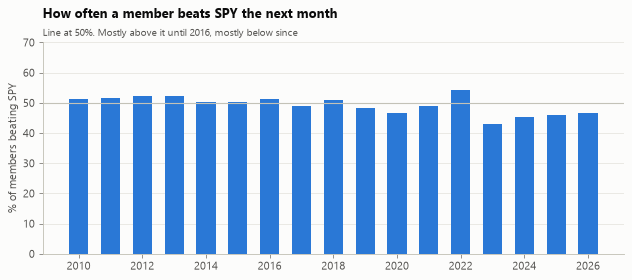

In [4]:
fig = plots.beat_rate_chart(by_year)
plots.save(fig, "beat_rate_by_year")

SPY is weighted by company size, so a handful of the largest stocks can carry it. In years when they
lead, most members trail the index even though the market rises.

The distribution of excess returns, per hold period:

In [5]:
eda.excess_quantiles(df)

,p1,p5,p25,p50,p75,p95,p99,mean,beat_rate,rows
1m,-0.1927,-0.1146,-0.0416,-0.0014,0.0390,0.1158,0.2046,-0.0005,0.4911,"87,470.0000"
3m,-0.3221,-0.2022,-0.0783,-0.0047,0.0689,0.2013,0.3634,-0.0022,0.4834,"86,464.0000"
6m,-0.4522,-0.2944,-0.1172,-0.0120,0.0943,0.2933,0.5683,-0.0050,0.4689,"84,955.0000"
12m,-0.6466,-0.4394,-0.1844,-0.0273,0.1341,0.4465,0.9060,-0.0101,0.4527,"81,937.0000"


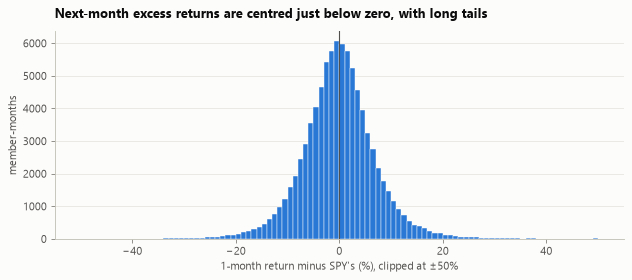

In [6]:
fig = plots.excess_hist_chart(df)
plots.save(fig, "excess_return_distribution")

Positions cut short because the company was delisted during the hold (valued at its last price,
then held as cash). This share grows as more delisted companies arrive from Alpha Vantage.

In [7]:
eda.truncation_by_hold(df)

,rows,cut_short,share
1m,"87,470.0000",0.0000,0.0000
3m,"86,464.0000",30.0000,0.0003
6m,"84,955.0000",69.0000,0.0008
12m,"81,937.0000",132.0000,0.0016


## 2. Which features carry signal? (2010–2022)

The **information coefficient (IC)** is the rank correlation, within one month, between a feature and the
next-month excess return, averaged over months. Stock-picking signals are small: an IC of 0.02–0.05 held
steadily is useful; a single feature at 0.1+ would suggest a leak.

Market and macro features have the same value for every stock in a month, so they can't rank stocks on
their own; they're studied in Section 3 instead.

In [8]:
research = eda.research_rows(df)
ic = eda.information_coefficients(research, FEATURES)
ic.to_csv(config.REPORTS_DIR / "feature_signal_2010_2022.csv")  # every feature; the top 20 below
print(f"{len(ic)} features with an IC; the full table is in reports/feature_signal_2010_2022.csv")
ic.head(20)

87 features with an IC; the full table is in reports/feature_signal_2010_2022.csv


,ic_mean,ic_std,t_stat,positive_months,months
ta_medprice,0.0223,0.1694,1.6458,0.5192,156.0000
ta_wclprice,0.0223,0.1694,1.6458,0.5192,156.0000
ta_typprice,0.0223,0.1694,1.6458,0.5192,156.0000
ta_avgprice,0.0206,0.1745,1.4721,0.4744,156.0000
ret_1m,-0.0199,0.1774,-1.4000,0.4808,156.0000
rs_spy_1m,-0.0199,0.1774,-1.4000,0.4808,156.0000
rank_ret_1m,-0.0199,0.1774,-1.4000,0.4808,156.0000
ta_bop,-0.0195,0.1655,-1.4707,0.5000,156.0000
rs_sector_1m,-0.0187,0.1329,-1.7613,0.4487,156.0000
ret_1m_z,-0.0171,0.1632,-1.3048,0.4872,156.0000


Some columns are the same signal under different names (a return and its rank give identical rank
correlations; several price transforms are identical on monthly bars). The chart shows each **distinct**
signal once and says how many identical copies it has.

87 features with an IC -> 72 distinct signals


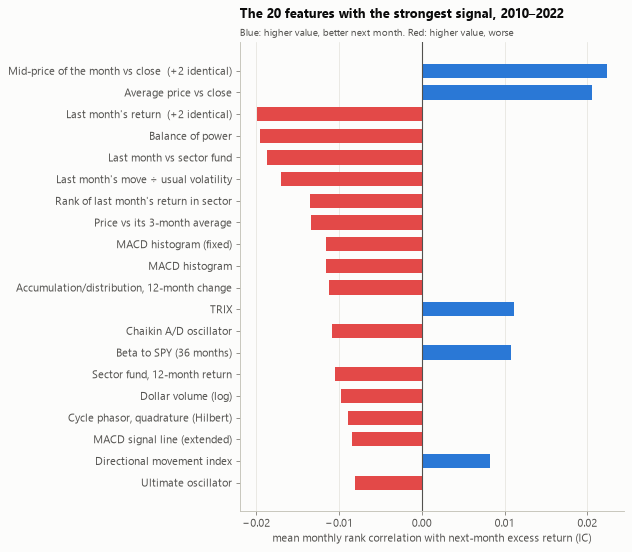

In [9]:
distinct = eda.distinct_signals(ic)
print(f"{len(ic)} features with an IC -> {len(distinct)} distinct signals")
fig = plots.ic_chart(distinct, n=20)
plots.save(fig, "ic_top20")

In [10]:
eda.ic_by_group(ic, FEATURE_SETS)

,features_with_ic,mean_abs_ic,strongest,strongest_ic
MARKET,3,0.0085,sector_etf_ret_12m,-0.0105
CROSS_SECTION,11,0.0081,rank_ret_1m,-0.0199
STOCK,14,0.0065,ret_1m_z,-0.0171
PAST_RETURNS,5,0.0062,ret_1m,-0.0199
TA,54,0.0058,ta_medprice,0.0223


Some features are the same signal in different clothes (e.g. a return and its rank give identical
rank correlations). Pairs correlated above 0.95 over 2010–2022:

In [11]:
pairs = eda.correlated_pairs(
    research.sample(20_000, random_state=0), [c for c in FEATURES if c in ic.index], threshold=0.95
)
print(f"{len(pairs)} pairs above 0.95")
pairs.head(15)

33 pairs above 0.95


,feature_a,feature_b,rho
0,ta_mom,ta_rocr,1.0000
1,ta_medprice,ta_wclprice,1.0000
2,ta_mom,ta_rocr100,1.0000
3,ta_roc,ta_rocr,1.0000
4,ta_roc,ta_rocp,1.0000
5,ta_mom,ta_roc,1.0000
6,ta_mom,ta_rocp,1.0000
7,ta_rocp,ta_rocr,1.0000
8,ta_roc,ta_rocr100,1.0000
9,ta_rocr,ta_rocr100,1.0000


### Does the signal hold up over time?

The mean IC of the strongest features in three sub-periods of the research window. A feature whose sign
flips between periods is unlikely to help out of sample.

In [12]:
periods = {
    "2010–14": ("2010-01-01", "2014-12-31"),
    "2015–19": ("2015-01-01", "2019-12-31"),
    "2020–22": ("2020-01-01", "2022-12-31"),
}
top = list(distinct.index[:10])  # the ten strongest distinct signals
stability = eda.ic_by_period(research, top, periods)
stability

,2010–14,2015–19,2020–22
ta_medprice,0.0114,0.0512,-0.0076
ta_avgprice,0.0063,0.0525,-0.0088
ret_1m,-0.0007,-0.0519,0.0015
ta_bop,-0.0000,-0.0537,0.0052
rs_sector_1m,-0.0109,-0.0335,-0.0071
ret_1m_z,-0.0001,-0.0441,-0.0002
sector_rank_ret_1m,-0.0077,-0.0276,0.0005
ma3_ratio,0.0058,-0.0434,0.0047
ta_macdfix_hist,-0.0034,-0.0162,-0.0178
ta_macd_hist,-0.0035,-0.0161,-0.0174


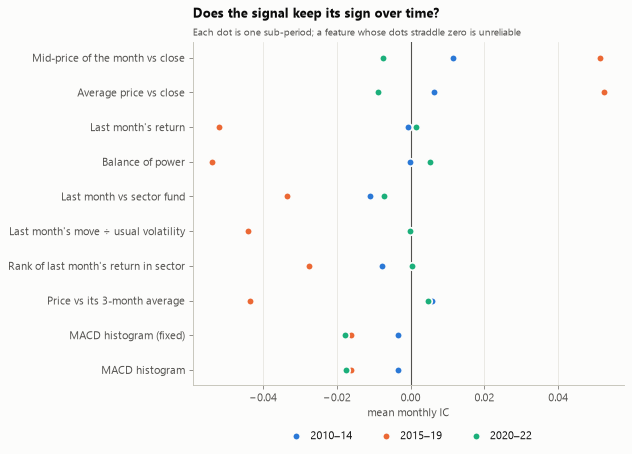

In [13]:
fig = plots.ic_stability_chart(stability)
plots.save(fig, "ic_stability")

## 3. When do last month's winners do well? (2010–2022)

The **winners' spread**: each month, the next-month excess return of the top 10 by last month's return,
minus that of all members. Then: which market-wide conditions (one value per month) go with a better or
worse spread?

In [14]:
spread = eda.winners_spread(research)
print(
    f"Months: {len(spread)}; mean spread {spread.mean():+.2%} a month; positive in {(spread > 0).mean():.0%} of months"
)
regime = eda.regime_correlations(
    research,
    spread,
    FEATURE_SETS["MARKET"]
    + FEATURE_SETS["MACRO"]
    + ["breadth_above_ma10", "dispersion_1m", "winners_excess_1m", "winners_excess_12m"],
)
regime.head(12).rename("spearman_with_spread").to_frame()

Months: 156; mean spread -0.02% a month; positive in 51% of months


,spearman_with_spread
mkt_spy_ret_12m,0.2611
mkt_spy_ret_6m,0.2334
sector_etf_ret_12m,0.2151
mkt_dji_ret_6m,0.1984
fedfunds,-0.1942
breadth_above_ma10,0.1934
mkt_dji_ret_12m,0.1930
gdppot_yoy,-0.1676
dgs1,-0.1659
gdppot_qoq,-0.1481


## 4. A first look at the plain rule (preview)

Each month-end, buy the top 1, 5 or 10 members by last month's return, equal weight, hold one month.
**No costs, no staggering, one hold period:** the full grid with costs and benchmarks is a separate step.
Survivorship bias is still present in the early years.

In [15]:
monthly = eda.plain_rule_returns(df)
eda.performance_summary(monthly)

,cagr,volatility,sharpe,max_drawdown,beats_benchmark,growth_of_1
top_1,0.1013,0.3975,0.4415,-0.5892,0.4677,5.0373
top_5,0.1457,0.2481,0.6753,-0.3790,0.5174,9.7665
top_10,0.1524,0.2180,0.7631,-0.3744,0.5323,10.7655
spy,0.1434,0.1481,0.9840,-0.2331,NaN,9.4327
equal_weight,0.1379,0.1607,0.8892,-0.3013,0.5124,8.7013


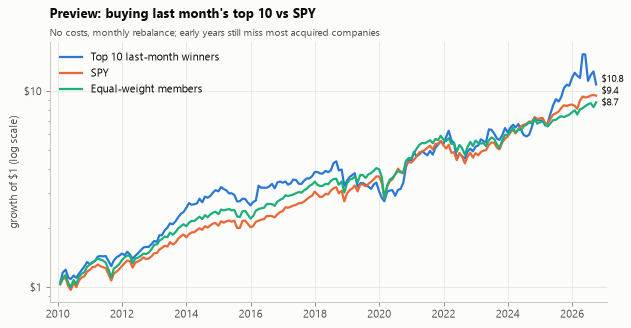

In [16]:
fig = plots.growth_chart(monthly)
plots.save(fig, "plain_rule_preview")

## 5. What this means for the next steps

- **No single feature is strong, and none is steady.** The largest ICs are around 0.02, and the
  stability table shows most of that signal comes from one stretch (2015–19), close to zero before and
  after. Any edge has to come from combining features and conditions, which is the models' job, and
  needs the time-series cross-validation planned for tuning.
- **Last month's return points the wrong way on average** (a negative IC: short-term reversal), yet the
  top-10 basket's preview return is close to or above SPY's, with clearly higher volatility and a deeper
  worst fall. The full rule grid (look-backs, holds, costs) will show whether that survives.
- **Several features duplicate each other** (the rate-of-change family, the price transforms, ATR and
  NATR, RSI and CMO). Trees cope; the logistic regression will need regularisation.
- **The market regime goes with the winners' payoff.** On average last month's top 10 do no better than
  the other members, but they do better after strong markets (SPY's 12-month return, breadth) and worse
  when interest rates are high. That supports the planned strategy of buying only when SPY is in an
  uptrend.

All of these are re-checked after the Alpha Vantage download finishes.